In [165]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression  
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, silhouette_score, davies_bouldin_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [6]:
df = pd.read_csv('Video_Games.csv')
df

,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8,192.0,Nintendo,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16714,Samurai Warriors: Sanada Maru,PS3,2016.0,Action,Tecmo Koei,0.00,0.00,0.01,0.00,0.01,NaN,NaN,NaN,NaN,NaN,NaN
16715,LMA Manager 2007,X360,2006.0,Sports,Codemasters,0.00,0.01,0.00,0.00,0.01,NaN,NaN,NaN,NaN,NaN,NaN
16716,Haitaka no Psychedelica,PSV,2016.0,Adventure,Idea Factory,0.00,0.00,0.01,0.00,0.01,NaN,NaN,NaN,NaN,NaN,NaN
16717,Spirits & Spells,GBA,2003.0,Platform,Wanadoo,0.01,0.00,0.00,0.00,0.01,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16719 entries, 0 to 16718
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16717 non-null  object 
 1   Platform         16719 non-null  object 
 2   Year_of_Release  16450 non-null  float64
 3   Genre            16717 non-null  object 
 4   Publisher        16665 non-null  object 
 5   NA_Sales         16719 non-null  float64
 6   EU_Sales         16719 non-null  float64
 7   JP_Sales         16719 non-null  float64
 8   Other_Sales      16719 non-null  float64
 9   Global_Sales     16719 non-null  float64
 10  Critic_Score     8137 non-null   float64
 11  Critic_Count     8137 non-null   float64
 12  User_Score       10015 non-null  object 
 13  User_Count       7590 non-null   float64
 14  Developer        10096 non-null  object 
 15  Rating           9950 non-null   object 
dtypes: float64(9), object(7)
memory usage: 2.0+ MB


In [8]:
df.isnull().sum()

Name                  2
Platform              0
Year_of_Release     269
Genre                 2
Publisher            54
NA_Sales              0
EU_Sales              0
JP_Sales              0
Other_Sales           0
Global_Sales          0
Critic_Score       8582
Critic_Count       8582
User_Score         6704
User_Count         9129
Developer          6623
Rating             6769
dtype: int64

# Data Cleaning

To begin data cleaning process, we have gone throughthe columns to see where there are null values. we also need to check for outliers, lies,
empty strings. To do this, we go through each column individually and clean and correct them.

* Name

In [9]:
# to clean the name colunm, I will start by inspecting it
# we currently have 16719 rows and only two have missing values
# we check for the unique values
df['Name'].unique()

array(['Wii Sports', 'Super Mario Bros.', 'Mario Kart Wii', ...,
       'Woody Woodpecker in Crazy Castle 5', 'LMA Manager 2007',
       'Haitaka no Psychedelica'], dtype=object)

In [10]:
df['Name'].isnull().sum()

np.int64(2)

In [11]:
# look through the rows with null values
df[df['Name'].isnull()]

,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
659,NaN,GEN,1993.0,NaN,Acclaim Entertainment,1.78,0.53,0.00,0.08,2.39,NaN,NaN,NaN,NaN,NaN,NaN
14246,NaN,GEN,1993.0,NaN,Acclaim Entertainment,0.00,0.00,0.03,0.00,0.03,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
# next, I will drop the 2 nan name rows. we have 16719 rows so dropping is better than imputing as we can't guess the names or give it
# unknown game.

print(f"Missing values in Name before: {df['Name'].isnull().sum()}")

Missing values in Name before: 2


In [14]:
df = df.dropna(subset=['Name'])

In [15]:
df['Name'].isnull().sum()

np.int64(0)

Next,
* Platform

In [16]:
# checking for null values
df['Platform'].isnull().sum()

np.int64(0)

In [17]:
# looking through all unique values
df['Platform'].unique()

array(['Wii', 'NES', 'GB', 'DS', 'X360', 'PS3', 'PS2', 'SNES', 'GBA',
       'PS4', '3DS', 'N64', 'PS', 'XB', 'PC', '2600', 'PSP', 'XOne',
       'WiiU', 'GC', 'GEN', 'DC', 'PSV', 'SAT', 'SCD', 'WS', 'NG', 'TG16',
       '3DO', 'GG', 'PCFX'], dtype=object)

In [18]:
print(f"Unique Platforms: {df['Platform'].nunique()}")

Unique Platforms: 31


Since Platform doesnot have lies or null values, we move to Year_of_Release

* Year_of_Release

In [19]:
# check for null values
df['Year_of_Release'].isnull().sum()

np.int64(269)

In [20]:
df['Year_of_Release'].unique()

array([2006., 1985., 2008., 2009., 1996., 1989., 1984., 2005., 1999.,
       2007., 2010., 2013., 2004., 1990., 1988., 2002., 2001., 2011.,
       1998., 2015., 2012., 2014., 1992., 1997., 1993., 1994., 1982.,
       2016., 2003., 1986., 2000.,   nan, 1995., 1991., 1981., 1987.,
       1980., 1983., 2020., 2017.])

In [21]:
print(df['Year_of_Release'].dtype)

float64


In [22]:
# the best thing to do here is to drop the nan rows instead of imputing to avoid wrong data

df = df.dropna(subset=['Year_of_Release'])

In [23]:
# next, they are all of type float
df['Year_of_Release'] = df['Year_of_Release'].astype(int)

In [25]:
print(df['Year_of_Release'].dtype)

int64


In [26]:
df['Year_of_Release'].isnull().sum()

np.int64(0)

next, 
* Genre

In [27]:
df['Genre'].isnull().sum()

# this shows that the initial 2 nan values in the Genre column were eliminated with the previous dropna carried out


np.int64(0)

In [28]:
# recheck the remaining null values
df.isnull().sum()

Name                  0
Platform              0
Year_of_Release       0
Genre                 0
Publisher            32
NA_Sales              0
EU_Sales              0
JP_Sales              0
Other_Sales           0
Global_Sales          0
Critic_Score       8465
Critic_Count       8465
User_Score         6608
User_Count         8985
Developer          6541
Rating             6679
dtype: int64

In [29]:
# checking the unique values for lies
df['Genre'].unique()

array(['Sports', 'Platform', 'Racing', 'Role-Playing', 'Puzzle', 'Misc',
       'Shooter', 'Simulation', 'Action', 'Fighting', 'Adventure',
       'Strategy'], dtype=object)

next, 
* Publisher

In [30]:
# we currently have 32 nan values in the Publisher, so dropping them as well is the right option
df['Publisher'].unique()

array(['Nintendo', 'Microsoft Game Studios', 'Take-Two Interactive',
       'Sony Computer Entertainment', 'Activision', 'Ubisoft',
       'Bethesda Softworks', 'Electronic Arts', 'Sega', 'SquareSoft',
       'Atari', '505 Games', 'Capcom', 'GT Interactive',
       'Konami Digital Entertainment', 'Square Enix',
       'Sony Computer Entertainment Europe', 'Virgin Interactive',
       'LucasArts', 'Warner Bros. Interactive Entertainment',
       'Universal Interactive', 'Eidos Interactive', 'RedOctane',
       'Vivendi Games', 'Enix Corporation', 'Namco Bandai Games',
       'Palcom', 'Hasbro Interactive', 'THQ', 'Fox Interactive',
       'Acclaim Entertainment', 'MTV Games', 'Disney Interactive Studios',
       'Codemasters', 'Majesco Entertainment', 'Red Orb', 'Level 5',
       'Arena Entertainment', 'Midway Games', 'JVC', 'Deep Silver',
       'NCSoft', '989 Studios', 'UEP Systems', 'Parker Bros.', 'Maxis',
       'Imagic', 'Tecmo Koei', 'ASCII Entertainment', 'Valve Software',
     

In [31]:
df = df.dropna(subset=['Publisher'])

In [32]:
# checking if there are empty strings
df[df['Publisher'] == ''].shape[0]

0

Next,

* NA_Sales

In [33]:
# checking for unique values, lies and empty strings are there are no null values

df['NA_Sales'].unique()

array([4.136e+01, 2.908e+01, 1.568e+01, 1.561e+01, 1.127e+01, 2.320e+01,
       1.128e+01, 1.396e+01, 1.444e+01, 2.693e+01, 9.050e+00, 9.710e+00,
       9.000e+00, 8.920e+00, 1.500e+01, 9.010e+00, 7.020e+00, 9.430e+00,
       1.278e+01, 4.740e+00, 6.380e+00, 1.083e+01, 9.540e+00, 9.660e+00,
       8.410e+00, 6.060e+00, 3.430e+00, 5.510e+00, 6.850e+00, 9.040e+00,
       5.890e+00, 6.030e+00, 9.700e+00, 5.280e+00, 4.990e+00, 8.250e+00,
       8.520e+00, 5.540e+00, 6.990e+00, 6.620e+00, 5.030e+00, 5.990e+00,
       3.960e+00, 2.500e+00, 7.970e+00, 6.910e+00, 4.340e+00, 4.350e+00,
       3.010e+00, 6.160e+00, 6.760e+00, 4.020e+00, 4.890e+00, 2.960e+00,
       4.760e+00, 5.010e+00, 6.730e+00, 5.950e+00, 3.660e+00, 5.550e+00,
       7.040e+00, 6.650e+00, 3.880e+00, 5.800e+00, 4.100e+00, 5.930e+00,
       4.360e+00, 5.700e+00, 2.030e+00, 4.400e+00, 5.050e+00, 3.540e+00,
       1.120e+00, 6.820e+00, 1.750e+00, 3.740e+00, 1.060e+00, 2.790e+00,
       2.910e+00, 9.900e-01, 2.570e+00, 2.990e+00, 

In [34]:
#checking for empty strings. it also has no negerative values 
df[df['NA_Sales'] == ''].shape[0]

0

In [37]:
df.isnull().sum()

Name                  0
Platform              0
Year_of_Release       0
Genre                 0
Publisher             0
NA_Sales              0
EU_Sales              0
JP_Sales              0
Other_Sales           0
Global_Sales          0
Critic_Score       8434
Critic_Count       8434
User_Score         6579
User_Count         8955
Developer          6512
Rating             6649
dtype: int64

In [38]:
# next, EU_Sales
df['EU_Sales'].unique()

array([2.896e+01, 3.580e+00, 1.276e+01, 1.093e+01, 8.890e+00, 2.260e+00,
       9.140e+00, 9.180e+00, 6.940e+00, 6.300e-01, 1.095e+01, 7.470e+00,
       6.180e+00, 8.030e+00, 4.890e+00, 8.490e+00, 9.090e+00, 4.000e-01,
       3.750e+00, 9.200e+00, 4.460e+00, 2.710e+00, 3.440e+00, 5.140e+00,
       5.490e+00, 3.900e+00, 5.350e+00, 3.170e+00, 5.090e+00, 4.240e+00,
       5.040e+00, 5.860e+00, 3.680e+00, 4.190e+00, 5.730e+00, 3.590e+00,
       4.510e+00, 2.550e+00, 4.020e+00, 4.370e+00, 6.310e+00, 3.450e+00,
       2.810e+00, 2.850e+00, 3.490e+00, 1.000e-02, 3.350e+00, 2.040e+00,
       3.070e+00, 3.870e+00, 3.000e+00, 4.820e+00, 3.640e+00, 2.150e+00,
       3.690e+00, 2.650e+00, 2.560e+00, 3.110e+00, 3.140e+00, 1.940e+00,
       1.950e+00, 2.470e+00, 2.280e+00, 3.420e+00, 3.630e+00, 2.360e+00,
       1.710e+00, 1.850e+00, 2.790e+00, 1.240e+00, 6.120e+00, 1.530e+00,
       3.470e+00, 2.240e+00, 5.010e+00, 2.010e+00, 1.720e+00, 2.070e+00,
       6.420e+00, 3.860e+00, 4.500e-01, 3.480e+00, 

In [41]:
df['JP_Sales'].unique()

array([3.770e+00, 6.810e+00, 3.790e+00, 3.280e+00, 1.022e+01, 4.220e+00,
       6.500e+00, 2.930e+00, 4.700e+00, 2.800e-01, 1.930e+00, 4.130e+00,
       7.200e+00, 3.600e+00, 2.400e-01, 2.530e+00, 9.800e-01, 4.100e-01,
       3.540e+00, 4.160e+00, 6.040e+00, 4.180e+00, 3.840e+00, 6.000e-02,
       4.700e-01, 5.380e+00, 5.320e+00, 5.650e+00, 1.870e+00, 1.300e-01,
       3.120e+00, 3.600e-01, 1.100e-01, 4.350e+00, 6.500e-01, 7.000e-02,
       8.000e-02, 4.900e-01, 3.000e-01, 2.660e+00, 2.690e+00, 4.800e-01,
       3.800e-01, 5.330e+00, 1.910e+00, 3.960e+00, 3.100e+00, 1.100e+00,
       1.200e+00, 1.400e-01, 2.540e+00, 2.140e+00, 8.100e-01, 2.120e+00,
       4.400e-01, 3.150e+00, 1.250e+00, 4.000e-02, 0.000e+00, 2.470e+00,
       2.230e+00, 1.690e+00, 1.000e-02, 3.000e+00, 2.000e-02, 4.390e+00,
       1.980e+00, 1.000e-01, 3.810e+00, 5.000e-02, 2.490e+00, 1.580e+00,
       3.140e+00, 2.730e+00, 6.600e-01, 2.200e-01, 3.630e+00, 1.450e+00,
       1.310e+00, 2.430e+00, 7.000e-01, 3.500e-01, 

In [42]:
df['Other_Sales'].unique()

array([8.450e+00, 7.700e-01, 3.290e+00, 2.950e+00, 1.000e+00, 5.800e-01,
       2.880e+00, 2.840e+00, 2.240e+00, 4.700e-01, 2.740e+00, 1.900e+00,
       7.100e-01, 2.150e+00, 1.690e+00, 1.770e+00, 3.960e+00, 1.057e+01,
       5.500e-01, 2.040e+00, 1.360e+00, 4.200e-01, 4.600e-01, 1.410e+00,
       1.780e+00, 5.000e-01, 1.180e+00, 8.000e-01, 1.160e+00, 1.320e+00,
       5.900e-01, 2.380e+00, 1.130e+00, 7.800e-01, 2.420e+00, 1.120e+00,
       1.280e+00, 1.570e+00, 1.300e+00, 1.010e+00, 9.100e-01, 1.790e+00,
       1.970e+00, 8.600e-01, 1.210e+00, 2.300e-01, 7.600e-01, 7.400e-01,
       7.530e+00, 2.900e-01, 1.030e+00, 5.200e-01, 2.110e+00, 1.600e+00,
       1.610e+00, 3.500e-01, 9.700e-01, 1.060e+00, 6.300e-01, 1.500e-01,
       7.900e-01, 9.600e-01, 1.250e+00, 9.000e-01, 8.100e-01, 3.900e-01,
       6.800e-01, 8.500e-01, 1.800e-01, 8.000e-02, 6.700e-01, 7.000e-01,
       4.100e-01, 3.300e-01, 6.000e-01, 5.400e-01, 1.730e+00, 1.230e+00,
       1.600e-01, 1.110e+00, 3.100e-01, 4.800e-01, 

In [43]:
df['Global_Sales'].unique()

array([8.253e+01, 4.024e+01, 3.552e+01, 3.277e+01, 3.137e+01, 3.026e+01,
       2.980e+01, 2.892e+01, 2.832e+01, 2.831e+01, 2.467e+01, 2.321e+01,
       2.310e+01, 2.270e+01, 2.181e+01, 2.179e+01, 2.104e+01, 2.081e+01,
       2.061e+01, 2.015e+01, 1.825e+01, 1.814e+01, 1.728e+01, 1.627e+01,
       1.615e+01, 1.585e+01, 1.529e+01, 1.514e+01, 1.498e+01, 1.473e+01,
       1.464e+01, 1.463e+01, 1.461e+01, 1.460e+01, 1.379e+01, 1.367e+01,
       1.347e+01, 1.332e+01, 1.310e+01, 1.284e+01, 1.266e+01, 1.263e+01,
       1.261e+01, 1.213e+01, 1.212e+01, 1.189e+01, 1.177e+01, 1.168e+01,
       1.166e+01, 1.135e+01, 1.118e+01, 1.101e+01, 1.095e+01, 1.081e+01,
       1.070e+01, 1.060e+01, 1.055e+01, 1.050e+01, 1.049e+01, 1.030e+01,
       1.025e+01, 1.012e+01, 9.900e+00, 9.870e+00, 9.860e+00, 9.720e+00,
       9.710e+00, 9.490e+00, 9.440e+00, 9.360e+00, 9.310e+00, 9.300e+00,
       9.180e+00, 9.160e+00, 8.910e+00, 8.790e+00, 8.760e+00, 8.570e+00,
       8.490e+00, 8.380e+00, 8.270e+00, 8.160e+00, 

Next,
* Critical_Score

Here, the missing rows values in this colunm are so many. but because this cleaning is a build up phase for predictive modelling and 
regression and many others, dropping these rows seems to be the best decision so we don't impute and endup with fake data for our
model learning and development.

Also, it is a primary feature for task B,C and D

In [44]:
# first, checking the number of null values in Critic_Score
print(f"Missing Critic_Scores before: {df['Critic_Score'].isnull().sum()}")

Missing Critic_Scores before: 8434


In [45]:
# dropping empty columns in the Crtical_Score colunm as it is a primary feature for task B, C and D and imputing will introduce fake information

df = df.dropna(subset=['Critic_Score'])

In [46]:
# rechecking the new number of missing rows in the Critic Colunm
print(f"Missing Critic_Scores before: {df['Critic_Score'].isnull().sum()}")

Missing Critic_Scores before: 0


In [47]:
# Confirming the new length of the dataframe

print(f"Current rows in dataset: {len(df)}")

Current rows in dataset: 7982


In [48]:
# rechecking null values in the remaining columns
# this shows how many other nan rows in other columns were affected, as dropping such a large number affects the whole dataframe

df.isnull().sum()

Name                  0
Platform              0
Year_of_Release       0
Genre                 0
Publisher             0
NA_Sales              0
EU_Sales              0
JP_Sales              0
Other_Sales           0
Global_Sales          0
Critic_Score          0
Critic_Count          0
User_Score           33
User_Count         1089
Developer             6
Rating               81
dtype: int64

Next, 
* User_Score

For this column, it is also a very critical column and does not need fake data. we first check for unique values and drop nan values

In [49]:
df['User_Score'].unique()

array(['8', '8.3', '8.5', '6.6', '8.4', '8.6', '7.7', '6.3', '7.4', '8.2',
       '9', '7.9', '8.1', '8.7', '7.1', '3.4', '5.3', '4.8', '3.2', '8.9',
       '6.4', '7.8', '7.5', '2.6', '7.2', '9.2', '7', '7.3', '4.3', '7.6',
       '5.7', '5', '9.1', '6.5', '8.8', '6.9', '9.4', '6.8', '6.1', '6.7',
       '5.4', nan, '4', '9.3', '6.2', '4.2', '6', 'tbd', '4.9', '3.7',
       '4.1', '5.8', '5.6', '5.5', '4.4', '4.6', '5.9', '3.9', '3.1',
       '2.9', '5.2', '3.3', '4.5', '5.1', '3.5', '2.5', '1.9', '2.2', '2',
       '9.5', '4.7', '2.1', '3.6', '1.8', '3.8', '3', '9.6', '2.8', '1.7',
       '2.7', '2.4', '1.5', '1.2', '2.3', '0.5', '0.6', '0.9', '1', '1.4',
       '1.3', '0.7'], dtype=object)

Based on this information, I can determine that User_Score has nan and tbd. tbd is not a number and it means to be determined.
So we need to convert it to nan as well. 

In [51]:
# to achieve this, converting all the User_Score values to numeric will also convert tbd to nan
df['User_Score'] = pd.to_numeric(df['User_Score'], errors='coerce')

In [52]:
# next, checking the new number of null values in the User_Score column
print(f"Total missing User_Scores: {df['User_Score'].isnull().sum()}")

Total missing User_Scores: 1089


In [53]:
# since we also need real data for this column, dropping it will be a good idea. as imputing here is risky

df = df.dropna(subset=['User_Score'])

In [54]:
print(f"Number of rows after dropping nans in User_Score: {len(df)}")

Number of rows after dropping nans in User_Score: 6893


In [55]:
df['User_Score'].unique()

array([8. , 8.3, 8.5, 6.6, 8.4, 8.6, 7.7, 6.3, 7.4, 8.2, 9. , 7.9, 8.1,
       8.7, 7.1, 3.4, 5.3, 4.8, 3.2, 8.9, 6.4, 7.8, 7.5, 2.6, 7.2, 9.2,
       7. , 7.3, 4.3, 7.6, 5.7, 5. , 9.1, 6.5, 8.8, 6.9, 9.4, 6.8, 6.1,
       6.7, 5.4, 4. , 9.3, 6.2, 4.2, 6. , 4.9, 3.7, 4.1, 5.8, 5.6, 5.5,
       4.4, 4.6, 5.9, 3.9, 3.1, 2.9, 5.2, 3.3, 4.5, 5.1, 3.5, 2.5, 1.9,
       2.2, 2. , 9.5, 4.7, 2.1, 3.6, 1.8, 3.8, 3. , 9.6, 2.8, 1.7, 2.7,
       2.4, 1.5, 1.2, 2.3, 0.5, 0.6, 0.9, 1. , 1.4, 1.3, 0.7])

In [56]:
# rechecking the columns with nulls after dropping 1089 columns due to nans in the User_Score
df.isnull().sum()

Name                0
Platform            0
Year_of_Release     0
Genre               0
Publisher           0
NA_Sales            0
EU_Sales            0
JP_Sales            0
Other_Sales         0
Global_Sales        0
Critic_Score        0
Critic_Count        0
User_Score          0
User_Count          0
Developer           4
Rating             68
dtype: int64

Next,
* User_Count

Now, we have no nans in User_Count.
    We will convert to interger

In [57]:
# Converting to integer to remove the decimal point
df['User_Count'] = df['User_Count'].astype(int)

In [58]:
df['User_Count'].isnull().sum()

np.int64(0)

Next, Critic_Score
Here, since there are no longer null values, Checking for lies and errors is next

In [59]:
df['Critic_Score'].unique()

array([76., 82., 80., 89., 58., 87., 91., 61., 97., 95., 77., 88., 83.,
       94., 93., 85., 86., 98., 96., 90., 84., 73., 74., 78., 92., 71.,
       72., 68., 62., 49., 67., 81., 66., 56., 79., 70., 59., 64., 75.,
       60., 63., 69., 50., 25., 42., 44., 48., 57., 29., 47., 65., 55.,
       54., 20., 53., 38., 33., 52., 30., 32., 43., 45., 40., 46., 51.,
       39., 34., 41., 36., 37., 31., 27., 35., 26., 19., 28., 23., 24.,
       21., 17., 13.])

In [60]:
# Here, the Critic_Score is a float. it needs to become an interger
print(df['Critic_Score'].dtype)

float64


In [61]:
df['Critic_Score'] = df['Critic_Score'].astype(int)

In [62]:
# thenconfirm the new data type
print(df['Critic_Score'].dtype)
df['Critic_Score'].unique()

int64


array([76, 82, 80, 89, 58, 87, 91, 61, 97, 95, 77, 88, 83, 94, 93, 85, 86,
       98, 96, 90, 84, 73, 74, 78, 92, 71, 72, 68, 62, 49, 67, 81, 66, 56,
       79, 70, 59, 64, 75, 60, 63, 69, 50, 25, 42, 44, 48, 57, 29, 47, 65,
       55, 54, 20, 53, 38, 33, 52, 30, 32, 43, 45, 40, 46, 51, 39, 34, 41,
       36, 37, 31, 27, 35, 26, 19, 28, 23, 24, 21, 17, 13])

Next, converting the Critic_Count to interger too

In [63]:
print(df['Critic_Count'].dtype)

float64


In [64]:
df['Critic_Count'] = df['Critic_Count'].astype(int)

In [65]:
# thenconfirm the new data type
print(df['Critic_Count'].dtype)
df['Critic_Count'].unique()

int64


array([ 51,  73,  65,  41,  80,  64,  63,  45,  33,  50,  58,  62,  37,
        54,  81,  89,  21, 100,  39,  56,  66,  57,  86,  74,  16,  82,
        67,  29,  15,  70,  99,  20,  87,  23,  24,  10,  27,  42,  91,
        53,  75,  46,  84,  38,  12,  90,  97,  44, 105,  77,  68,  28,
        94,  96,  61,  22,  88,  47,  98,  85,  13,   8,  95,  17,  35,
        19,  48,  14, 113,  83,  72,  30,  69,  76,  18,  34,  40, 101,
         9,  32,  78,  36,  25,  59,  31,  79,  26,  49,  60,  11,  43,
       107,   7,  71,  55,  52,  92,   4,  93,   5,   6, 103, 102, 106,
         3, 104])

In [66]:
print(df['User_Score'].dtype)

float64


In [67]:
# rechecking the number of nulls in the columns
df.isnull().sum()

Name                0
Platform            0
Year_of_Release     0
Genre               0
Publisher           0
NA_Sales            0
EU_Sales            0
JP_Sales            0
Other_Sales         0
Global_Sales        0
Critic_Score        0
Critic_Count        0
User_Score          0
User_Count          0
Developer           4
Rating             68
dtype: int64

Next,
* Developer
Currently has only 4 missing values.
Dropping them as nan is also good as to prevent fake data

In [68]:
df[df['Developer'].isnull()]

,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
5929,AMF Bowling 2004,XB,2003,Sports,Mud Duck Productions,0.22,0.06,0.0,0.01,0.30,48,6,4.4,8,NaN,NaN
8778,Blitz: The League II,PS3,2008,Sports,Midway Games,0.11,0.02,0.0,0.02,0.15,62,25,7.5,15,NaN,NaN
10697,Harry Potter and the Deathly Hallows - Part 2,PC,2011,Action,Electronic Arts,0.05,0.04,0.0,0.01,0.10,43,12,5.0,56,NaN,NaN
14654,The Wolf Among Us,X360,2011,Adventure,Telltale Games,0.01,0.02,0.0,0.00,0.03,83,5,7.7,88,NaN,NaN


In [69]:
# Drop the final 4 rows with missing Developer values
df = df.dropna(subset=['Developer'])

In [70]:
# rechecking the number of nulls in the columns
df.isnull().sum()

Name                0
Platform            0
Year_of_Release     0
Genre               0
Publisher           0
NA_Sales            0
EU_Sales            0
JP_Sales            0
Other_Sales         0
Global_Sales        0
Critic_Score        0
Critic_Count        0
User_Score          0
User_Count          0
Developer           0
Rating             64
dtype: int64

Next, 
* Rating

In [71]:
# Dropping the 64 nans is the best as it takes away imputting fake and unreliable data since we need it for modelling
df['Rating'].unique()

array(['E', 'M', 'T', 'E10+', nan, 'AO', 'K-A', 'RP'], dtype=object)

In [72]:
# Dropping the final 64 rows with missing Ratings
df = df.dropna(subset=['Rating'])

In [73]:
print(df.isnull().sum())
print(f"\nTotal clean rows for the Portfolio: {len(df)}")

Name               0
Platform           0
Year_of_Release    0
Genre              0
Publisher          0
NA_Sales           0
EU_Sales           0
JP_Sales           0
Other_Sales        0
Global_Sales       0
Critic_Score       0
Critic_Count       0
User_Score         0
User_Count         0
Developer          0
Rating             0
dtype: int64

Total clean rows for the Portfolio: 6825


In [74]:
df['Rating'].unique()

array(['E', 'M', 'T', 'E10+', 'AO', 'K-A', 'RP'], dtype=object)

In [75]:
df['Rating'].value_counts()

Rating
T       2377
E       2082
M       1433
E10+     930
AO         1
K-A        1
RP         1
Name: count, dtype: int64

K-A has only 1 value, K-A is same as E as it is the former rating
RP which means Rating pending can actually be taken as nan
so converting it to nan is best

In [77]:
# first, replacing K-A to E since they are same
df['Rating'] = df['Rating'].replace('K-A', 'E')

In [78]:
# next, replacing RP to nan since it means rating pending
df['Rating'] = df['Rating'].replace('RP', np.nan)

In [79]:
# next, dropping this new nan value in rating
df = df.dropna(subset=['Rating'])

In [80]:
df['Rating'].value_counts()

Rating
T       2377
E       2083
M       1433
E10+     930
AO         1
Name: count, dtype: int64

# Exploratory Data Analysis

In this exploratory Data Analysis, I will also carry out visualization, correlation and mapping, which is a prerequisite for component 1

* a.
 While you explore the data, what correlation exists and what features are mostly
important for predicting the sales performance of video games. The exploratory data
analysis must include a minimum of two (2) visuals (for example: heatmap, boxplot or
any other) 

* Inother to find the Correlation that exist, calculating the correlation is key

* Correlation Heatmap

In [81]:
# first is to select all the columns that are numerical
# using select_dtypes(include=[np.number]) would achieve this
numerical_df = df.select_dtypes(include=[np.number])
numerical_df

,Year_of_Release,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count
0,2006,41.36,28.96,3.77,8.45,82.53,76,51,8.0,322
2,2008,15.68,12.76,3.79,3.29,35.52,82,73,8.3,709
3,2009,15.61,10.93,3.28,2.95,32.77,80,73,8.0,192
6,2006,11.28,9.14,6.50,2.88,29.80,89,65,8.5,431
7,2006,13.96,9.18,2.93,2.84,28.92,58,41,6.6,129
...,...,...,...,...,...,...,...,...,...,...
16667,2001,0.01,0.00,0.00,0.00,0.01,46,4,2.4,21
16677,2002,0.01,0.00,0.00,0.00,0.01,81,12,8.8,9
16696,2014,0.00,0.01,0.00,0.00,0.01,80,20,7.6,412
16700,2011,0.01,0.00,0.00,0.00,0.01,61,12,5.8,43


In [82]:
# calculating the correlation matrix. Here, I use the list of numerical columns already gotten
correlation_matrix = numerical_df.corr()
correlation_matrix

,Year_of_Release,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count
Year_of_Release,1.000000,-0.016189,0.041385,-0.038418,0.042351,0.006708,-0.007596,0.203468,-0.253895,0.199390
NA_Sales,-0.016189,1.000000,0.841805,0.468601,0.726754,0.955792,0.233557,0.283884,0.085782,0.246197
EU_Sales,0.041385,0.841805,1.000000,0.519924,0.716326,0.939312,0.213085,0.265718,0.055904,0.283496
JP_Sales,-0.038418,0.468601,0.519924,1.000000,0.394818,0.613542,0.147300,0.168281,0.127514,0.072765
Other_Sales,0.042351,0.726754,0.716326,0.394818,1.000000,0.804025,0.191494,0.239493,0.057073,0.240078
Global_Sales,0.006708,0.955792,0.939312,0.613542,0.804025,1.000000,0.237534,0.290367,0.088335,0.264141
Critic_Score,-0.007596,0.233557,0.213085,0.147300,0.191494,0.237534,1.000000,0.396441,0.580313,0.265626
Critic_Count,0.203468,0.283884,0.265718,0.168281,0.239493,0.290367,0.396441,1.000000,0.195065,0.365593
User_Score,-0.253895,0.085782,0.055904,0.127514,0.057073,0.088335,0.580313,0.195065,1.000000,0.017536
User_Count,0.199390,0.246197,0.283496,0.072765,0.240078,0.264141,0.265626,0.365593,0.017536,1.000000


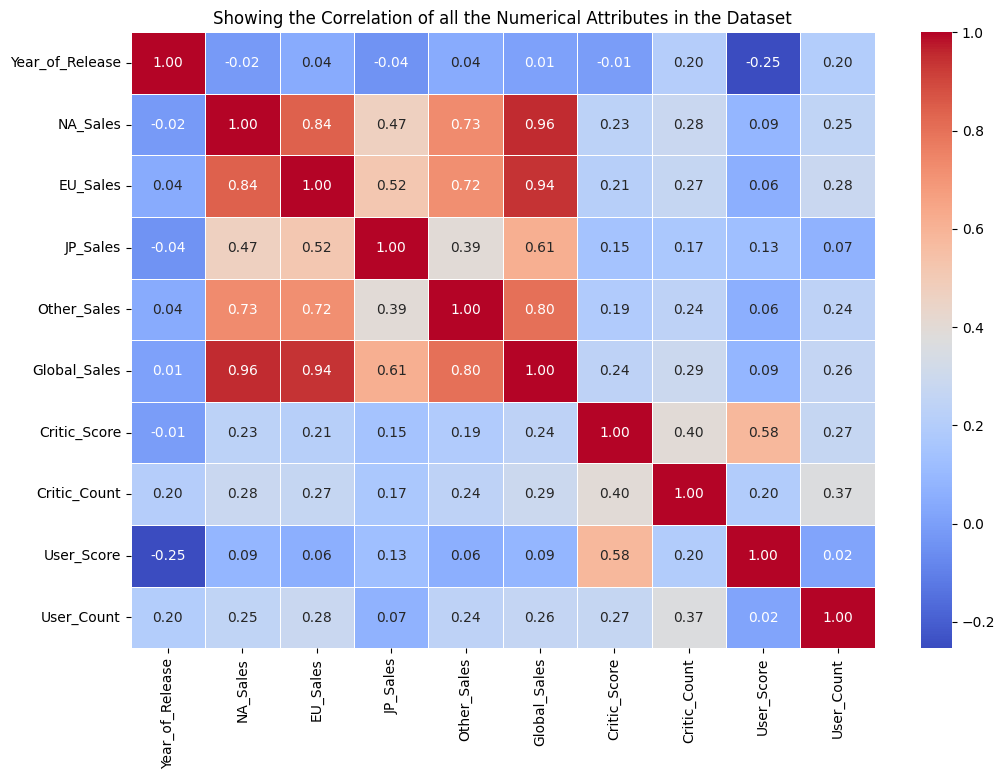

In [83]:
# Next, plotting the heatmap so that I can get the correlation

plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidth=0.5)
plt.title("Showing the Correlation of all the Numerical Attributes in the Dataset")
plt.show()

In [84]:
# for Global Sales specifically, to show the correlations, I use the correlation matrix and sort the values
print("Correlations with Global_Sales:")
print(correlation_matrix['Global_Sales'].sort_values(ascending=False))

Correlations with Global_Sales:
Global_Sales       1.000000
NA_Sales           0.955792
EU_Sales           0.939312
Other_Sales        0.804025
JP_Sales           0.613542
Critic_Count       0.290367
User_Count         0.264141
Critic_Score       0.237534
User_Score         0.088335
Year_of_Release    0.006708
Name: Global_Sales, dtype: float64


Next, in other to see the how the Genre affects the Global sales, showing the distribution of sales is good

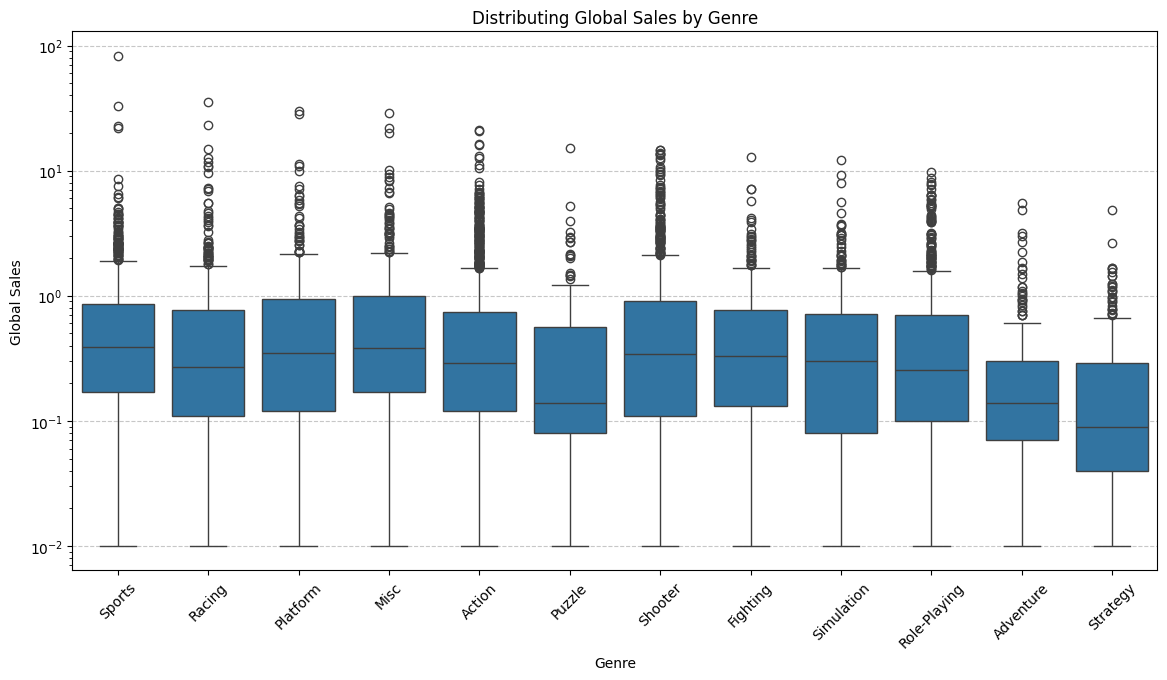

In [85]:
# using matplotlib for this
plt.figure(figsize=(14, 7))

# Since global sales have extreme values, more like outliers, I use a log scale in seaborn
sns.boxplot(x='Genre', y='Global_Sales', data=df)
plt.yscale('log')

# adding title so it is easier for other people to understand
plt.title('Distributing Global Sales by Genre')

# adding labels so it's easier to read and understand
plt.ylabel('Global Sales')
plt.xlabel('Genre')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

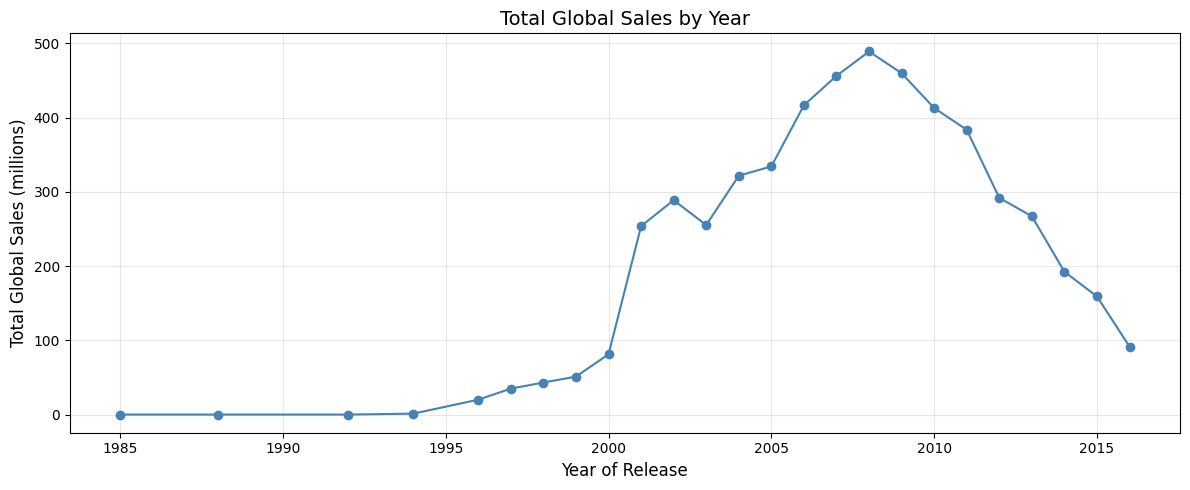

In [87]:
# firslt I calculate the yearly sales
yearly_sales = df.groupby('Year_of_Release')['Global_Sales'].sum()

# then i get the figure to plot with
plt.figure(figsize=(12, 5))
plt.plot(yearly_sales.index, yearly_sales.values, marker='o', color='steelblue')

# I both label and title the char
plt.title('Total Global Sales by Year', fontsize=14)
plt.xlabel('Year of Release', fontsize=12)
plt.ylabel('Total Global Sales (millions)', fontsize=12)
plt.grid(True, alpha=0.3)

# using a grid layout
plt.tight_layout()
plt.savefig('sales_trend.png', dpi=150)
plt.show()

* # b. Compare regression models using
  
(i) single numerical input features and 

(ii) multiple numerical input features to predict the Global Sales of video games. 

For each individual numerical feature, determine whether Global Sales is better modelled using a linear 
regression or a nonlinear approach (e.g., polynomial regression). 

Then evaluate whether combining multiple numerical features improves predictive performance. Present your findings in a 
comparative table using appropriate evaluation metrics (e.g., RMSE,MAE, R²), and briefly interpret the results. 

* # (i) single numerical input features and

* Since there are 5 numerical input features from the dataset, I will loop through them to be able to compare a linear model and a polynomial
model

In [109]:
# Since our focus is on the Global Sales, we'd make global sales the main focus target.
target_focus = 'Global_Sales'

# next, since all the sales like NA_Sales, EU_Sales, JP_Sales, Other_Sales are part of Global Sales, we need to leave them out
# now, we are left with
features_num = ['Year_of_Release', 'Critic_Count', 'User_Score', 'Critic_Score', 'User_Count']

In [110]:
# the next thing is to split the data into test data and train data
# ensuring the data is split correctly, using  80% for training and 20% testing

# Define the X, y variables

X = df[features_num]
y = df[target_focus]

# Called the parameters needed
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [111]:
# next, we need to calculate the metrics with RMSE, MAE, mae, and r2
def get_metrics(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return rmse, mae, r2

* Comparing both linear regression and Polynomial Regression. this is to allow us get the single numerical input features

In [112]:
# I loop through the features_num we initially created with the non-sales numerical features
# Since there are 5 numerical input features from the dataset, I will loop through them to be 
# able to compare a linear model and a polynomial model

results_count = []


for feature in features_num:
    # for linear regression
    # first, create a new instance model of the LinearRegression model
    model_linear = LinearRegression()
    model_linear.fit(X_train[[feature]], y_train)
    # next, I need to define the y prediction linea regression
    y_pred_linear = model_linear.predict(X_test[[feature]])
    rmse_linear, mae_linear, r2_linear = get_metrics(y_test, y_pred_linear)
    results_count.append({'Model': 'Linear', 'Feature': feature, 'RMSE': rmse_linear, 'MAE':mae_linear, 'R2': r2_linear})

    # next, we define same for polynomial regression
    poly = PolynomialFeatures(degree=2)
    X_train_poly = poly.fit_transform(X_train[[feature]])
    X_test_poly = poly.transform(X_test[[feature]])

    # we need to create the polynomial regression model and also fit it properly
    model_polynomial = LinearRegression()
    model_polynomial.fit(X_train_poly, y_train)
    # now, we need to predict the model
    y_pred_poly = model_polynomial.predict(X_test_poly)
    rmse_poly, mae_poly, r2_poly = get_metrics(y_test, y_pred_poly)

    # the next thing to do here is to finally add them all to a bucket that we initially created, results_count
    results_count.append({'Model': 'Polynomial', 'Feature': feature, 'RMSE': rmse_poly, 'MAE': mae_poly, 'R2': r2_poly})
    print(results_count)

[{'Model': 'Linear', 'Feature': 'Year_of_Release', 'RMSE': np.float64(1.649193238964371), 'MAE': 0.8191016548312781, 'R2': -0.0007929353219207069}, {'Model': 'Polynomial', 'Feature': 'Year_of_Release', 'RMSE': np.float64(1.648985402793828), 'MAE': 0.8191581393658086, 'R2': -0.0005407054924215782}]
[{'Model': 'Linear', 'Feature': 'Year_of_Release', 'RMSE': np.float64(1.649193238964371), 'MAE': 0.8191016548312781, 'R2': -0.0007929353219207069}, {'Model': 'Polynomial', 'Feature': 'Year_of_Release', 'RMSE': np.float64(1.648985402793828), 'MAE': 0.8191581393658086, 'R2': -0.0005407054924215782}, {'Model': 'Linear', 'Feature': 'Critic_Count', 'RMSE': np.float64(1.5433607203832471), 'MAE': 0.7450631403344784, 'R2': 0.12353207883624528}, {'Model': 'Polynomial', 'Feature': 'Critic_Count', 'RMSE': np.float64(1.5292301024486488), 'MAE': 0.7174073726714071, 'R2': 0.13950804097736946}]
[{'Model': 'Linear', 'Feature': 'Year_of_Release', 'RMSE': np.float64(1.649193238964371), 'MAE': 0.819101654831278

* # ii) multiple numerical input features to predict the Global Sales of video games.

For this second part, the goal is to create a multi numerical input feature model

Here, since it is to predict performance improvement, we create the model without the single numerical input features to find out if the multiple numerical input features gives a better result

In [113]:
# in other to create a multi model, we need to still call the LinearRegression model to create a new instance
model_multi = LinearRegression()

# another thing that is important is fitting this model
model_multi.fit(X_train, y_train)

LinearRegression()

In [114]:
# then next, to predit with the test data
y_pred_multi = model_multi.predict(X_test)

In [99]:
# the next thing to do is to get the metrics of the test data
rmse_multi, mae_multi, r2_multi = get_metrics(y_test, y_pred_multi)

In [115]:
# then lastly append this results to the results_count as an object so we can easily compare with the others
results_count.append({'Model': 'Multiple Linear', 'Feature': 'All Numerical', 'RMSE': rmse_multi, 'MAE': mae_multi, 'R2': r2_multi})

* Comparative Table and Analysis

Here, I consider the results of the 3 model development with LinearRegression to create a linear, polynomial and multi numerical feature
model

In [116]:
# the first thing is to use the appended objects in results_count to create a dataframe in pandas
regression_finals = pd.DataFrame(results_count)

In [117]:
# Displaying the results to see the actual comparison
print('Comparing regression models:')
display(regression_finals)

Comparing regression models:


,Model,Feature,RMSE,MAE,R2
0,Linear,Year_of_Release,1.649193,0.819102,-0.000793
1,Polynomial,Year_of_Release,1.648985,0.819158,-0.000541
2,Linear,Critic_Count,1.543361,0.745063,0.123532
3,Polynomial,Critic_Count,1.529230,0.717407,0.139508
4,Linear,User_Score,1.646172,0.803295,0.002870
5,Polynomial,User_Score,1.645143,0.805703,0.004117
6,Linear,Critic_Score,1.568169,0.782122,0.095128
7,Polynomial,Critic_Score,1.516916,0.726115,0.153310
8,Linear,User_Count,1.531759,0.757977,0.136660
9,Polynomial,User_Count,1.528240,0.739591,0.140622


In [118]:
# the final thing is to create a csv file with this new data since they are already dictionaries
regression_finals.to_csv('regression_models_results.csv', index=False)

In [119]:
print("\nMultiple Feature Linear Regression:")
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred_multi)), 4))
print("MAE: ", round(mean_absolute_error(y_test, y_pred_multi), 4))
print("R2:  ", round(r2_score(y_test, y_pred_multi), 4))


Multiple Feature Linear Regression:
RMSE: 1.4585
MAE:  0.7192
R2:   0.2172


* # c. Building on your analysis in part (a), incorporate all relevant input variables (both numerical and categorical)

to develop a comprehensive regression model for predicting Global Sales. You must clearly justify your encoding strategy for categorical 

variables and your choice of regression algorithm (e.g., Random Forest, Gradient Boosting, or another suitable method). Using a table, 

compare the performance of this model with those developed in part (b) using appropriate evaluation metrics (e.g., RMSE, MAE,
                                                                                                             
R²). Critically evaluate whether including categorical variables and using a more advanced model improves predictive performance. 

* So we need to now use the categorical variables and the numerical variables. Because of this, I introduct RandomForest

In [121]:
# before using random variables, categorical data are not in numbers and the randomforest algorithm or even the linearregression algorithm
# can not understand it. so changing it to 1s and 0s is the best option here

# copying first
df_copy = df.copy()

In [ ]:
# next the use one hot encoding to convert the categorical data to 1s and 0s.

# the categorical data in this column are: Genre, Platform, Rating, Publishers, Developers.
# Publishers and Developers are too much so I will stick with Genre, Platform and Rating

* One of the first reasons for using One-Hot Encoding is that it can change categorical data to 1s and 0s.
* Another reason is that the binary it creates is interpretable and model-friendly
* Instead of using One-hot encoding on the Publisher, since it will be too large, using the label encoding is better.
* Label Encoding can help to give the publisher a number for each value
* But for the Developer, no need to use it as it has about 1288 unique values, and this would be too large

In [122]:
# to proceed, starting with One-Hot Encoding is good
df_copy = pd.get_dummies(df_copy, columns=['Genre', 'Platform', 'Rating'])

In [123]:
# the next thing is to create an instance of the LabelEncoder()
labelEncoder = LabelEncoder()

In [124]:
# next, creating a new column in the df_copy and then fit_transforming the Publisher into it
df_copy['Publisher_encoded'] = labelEncoder.fit_transform(df_copy['Publisher'])

* Now, definding the features and target is very essential

In [125]:
# first the numerical data based on my previous analysis are
numerical_features = ['Year_of_Release', 'Critic_Score', 'Critic_Count', 'User_Score', 'User_Count']

In [128]:
# then for Categorical data
['Genre_', 'Platform_', 'Rating_']

# looping through the whole dataframe to get only the categorical data
categorical_features = [categorical for categorical in df_copy.columns if categorical.startswith(('Genre_', 'Platform_', 'Rating_'))]

In [129]:
print(categorical_features)

['Genre_Action', 'Genre_Adventure', 'Genre_Fighting', 'Genre_Misc', 'Genre_Platform', 'Genre_Puzzle', 'Genre_Racing', 'Genre_Role-Playing', 'Genre_Shooter', 'Genre_Simulation', 'Genre_Sports', 'Genre_Strategy', 'Platform_3DS', 'Platform_DC', 'Platform_DS', 'Platform_GBA', 'Platform_GC', 'Platform_PC', 'Platform_PS', 'Platform_PS2', 'Platform_PS3', 'Platform_PS4', 'Platform_PSP', 'Platform_PSV', 'Platform_Wii', 'Platform_WiiU', 'Platform_X360', 'Platform_XB', 'Platform_XOne', 'Rating_AO', 'Rating_E', 'Rating_E10+', 'Rating_M', 'Rating_T']


In [131]:
# next is to combine all the features, both the numerical and categorical features
features_all = numerical_features + categorical_features + ['Publisher_encoded']

print(f"Totall features so far: {len(features_all)}")
print(f"Numerical Features: {len(numerical_features)}")
print(f"Categorical (encoded): {len(categorical_features) + 1}")

Totall features so far: 40
Numerical Features: 5
Categorical (encoded): 35


* The next step is to train and also test the models using the train/ test split

In [133]:
# train/ test spliting
X = df_copy[features_all]
y = df_copy['Global_Sales']

# Here, I use 80% for training, 20% for testing and a random_state of 42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

* The next step is to train the regression model. I have chosen to use random forest and, hence, train a random forest regressor because
Random forest is good for handling both numerical and categorical features, so it is not only good for numerical but also categorical.
    Random forest can also handle outliers well, and this is very key for our game sales data skewness. 
    Also, random forest is able to capture non-linear relationships between the features. So it is not only dealing with linear but can deal
    with both linear and non-linear.
    Another reason I have chosen random forest is that it can give me the scores of feature importance, and it is not easily affected by 
    overfitting. Also, random forest is many decision trees together, hence it really handles overfitting unlike a single decision tree

In [134]:
# the first thing here is to create a random forest regression model
randf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# next, I fit the model properly using the X_train and the y_train
randf_model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

* Now, this is the model evaluation phase. Here, I will have to predict the model then evaluate its metrics

In [136]:
# Predicting the model
y_pred_randf = randf_model.predict(X_test)

In [139]:
# defining the various error metrics of the model
rmse_randf = round(np.sqrt(mean_squared_error(y_test, y_pred_randf)), 4)
mae_randf = round(mean_absolute_error(y_test, y_pred_randf), 4)
r2_randf = round(r2_score(y_test, y_pred_randf), 4)

print(f"Random Forest RMSE: {rmse_randf}")
print(f"Random Forest MAE: {mae_randf}")
print(f"Random Forest R2: {r2_randf}")

Random Forest RMSE: 1.2419
Random Forest MAE: 0.5112
Random Forest R2: 0.4324


* Now, I have developed a random forest regression model. I will compare the models I have developed so far:
Linear regression model, Polynomial Regression Model, Multiple Linear model, Random Forest model.

In [140]:
# Displaying the previous results again to see the actual comparison, so I can use it for the table
print('Comparing regression models:')
display(regression_finals)

Comparing regression models:


,Model,Feature,RMSE,MAE,R2
0,Linear,Year_of_Release,1.649193,0.819102,-0.000793
1,Polynomial,Year_of_Release,1.648985,0.819158,-0.000541
2,Linear,Critic_Count,1.543361,0.745063,0.123532
3,Polynomial,Critic_Count,1.529230,0.717407,0.139508
4,Linear,User_Score,1.646172,0.803295,0.002870
5,Polynomial,User_Score,1.645143,0.805703,0.004117
6,Linear,Critic_Score,1.568169,0.782122,0.095128
7,Polynomial,Critic_Score,1.516916,0.726115,0.153310
8,Linear,User_Count,1.531759,0.757977,0.136660
9,Polynomial,User_Count,1.528240,0.739591,0.140622


In [147]:
# using pandas dataframe for this comparison table. I will use the Critical Score values for the single models: Linear, Polynomial
model_compare = pd.DataFrame([
    {'Model': 'Linear Regression',     'Features': 'Single, using Critical Score', 'RMSE': 1.5682,     'MAE': 0.7821,    'R2': 0.0951},
    {'Model': 'Polynomial Regression', 'Features': 'Single, using Critical Score', 'RMSE': 1.5169,     'MAE': 0.7261,    'R2': 0.1533},
    {'Model': 'Multiple Linear Reg',   'Features': 'Numerical for All',            'RMSE': 1.4585,     'MAE': 0.7192,    'R2': 0.2172},
    {'Model': 'Random Forest',         'Features': 'Numerical + Categorical',      'RMSE': rmse_randf, 'MAE': mae_randf, 'R2': r2_randf},
])

In [149]:
print("\nComparison Table for Part b and Part c models:")
display(model_compare)


Comparison Table for Part b and Part c models:


,Model,Features,RMSE,MAE,R2
0,Linear Regression,"Single, using Critical Score",1.5682,0.7821,0.0951
1,Polynomial Regression,"Single, using Critical Score",1.5169,0.7261,0.1533
2,Multiple Linear Reg,Numerical for All,1.4585,0.7192,0.2172
3,Random Forest,Numerical + Categorical,1.2419,0.5112,0.4324


* This comparison table above is good because the R2 score of Random Forest is way better than that of multiple Linear regression. 0.42324,
better than 0.2172, which means the model is now 43% better that 21%. Now the model can explain nearly 43% of the variance in global sales 
compared to the 21% previously. This is because I used both numerical and categorical features, providing the model with more context for the 
actual datapoints.

* Also, the average error has dropped from task b to task c. In task b, the average error RMSE was best at 1.4585, but in task c, using the random forest model, the average error has dropped to 1.2419, meaning that the model is getting closer to the actual sales figures. It is necessary.


* Also, seeing that the R2, which I understand as the percentage determining the understanding of the model, as it is the coefficient of determination, it more than doubled in task c with random forest when I added categorical data, Genre, Platform, and rating. This means that this data is a crucial predictor and very useful in the video game industry.

* The next thing to do is to plot the feature importance so that we can see which features are the most useful to the random forest. I will also use the inbuilt attribute of random forest feature_importances_ which was gotten from the Sckit-learn 

In [155]:
# plotting with matplotlib.pyplot to check the important features
# first, using the pandas series to check for the important features and defining the important feature variable


important_features = pd.Series(randf_model.feature_importances_, index=features_all)
print(important_features)

Year_of_Release       0.075501
Critic_Score          0.084072
Critic_Count          0.084842
User_Score            0.047115
User_Count            0.284970
Genre_Action          0.003298
Genre_Adventure       0.000311
Genre_Fighting        0.001937
Genre_Misc            0.013098
Genre_Platform        0.003648
Genre_Puzzle          0.000801
Genre_Racing          0.012149
Genre_Role-Playing    0.001775
Genre_Shooter         0.005582
Genre_Simulation      0.003616
Genre_Sports          0.075705
Genre_Strategy        0.000311
Platform_3DS          0.005023
Platform_DC           0.000226
Platform_DS           0.039681
Platform_GBA          0.000797
Platform_GC           0.000587
Platform_PC           0.042555
Platform_PS           0.000961
Platform_PS2          0.010981
Platform_PS3          0.002088
Platform_PS4          0.000732
Platform_PSP          0.001167
Platform_PSV          0.000044
Platform_Wii          0.094586
Platform_WiiU         0.000313
Platform_X360         0.002824
Platform

In [156]:
# then I will find the top features from the important features I have just defined
features_top = important_features.sort_values(ascending=False).head(15)
print(features_top)

User_Count           0.284970
Platform_Wii         0.094586
Critic_Count         0.084842
Critic_Score         0.084072
Genre_Sports         0.075705
Year_of_Release      0.075501
Rating_E             0.058268
User_Score           0.047115
Platform_PC          0.042555
Platform_DS          0.039681
Publisher_encoded    0.029385
Genre_Misc           0.013098
Genre_Racing         0.012149
Platform_PS2         0.010981
Genre_Shooter        0.005582
dtype: float64


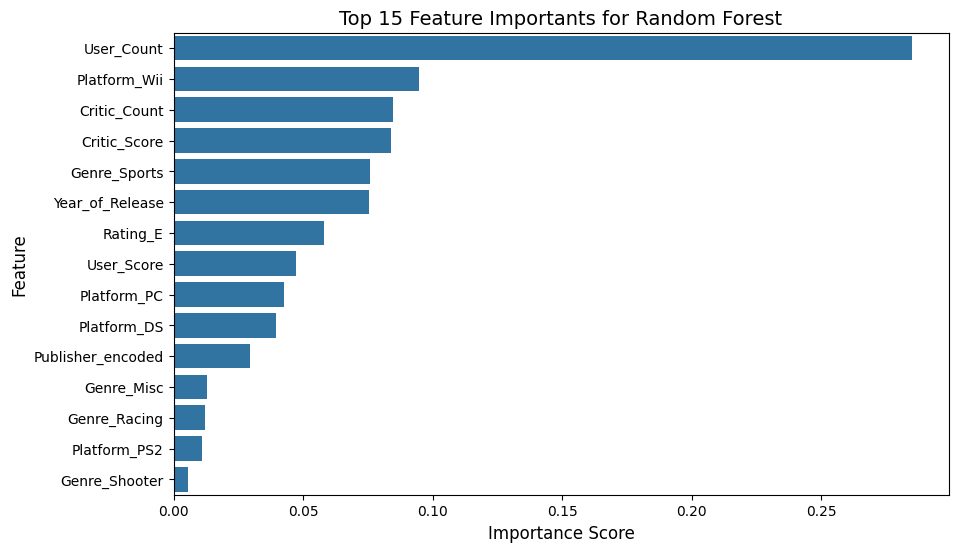

In [164]:
# plotting visualization to fully understand this feature importance

plt.figure(figsize=(10, 6))
sns.barplot(x=features_top.values, y=features_top.index)
plt.title('Top 15 Feature Importants for Random Forest', fontsize=14)
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.show()

* From this plot, this barplot,It can be seen that the User_Count has a very high feature importance score. This means that the number of
players and those that rated have a strong influence in predicting the game sales.

    Also, Critic_Count, Critic_score, Year_of_Release, Categorical Impact and many others

* # Task D

* d. Apply at least one clustering algorithm to identify key clustered insights within the
video game sales dataset.

Experiment with different combinations of numerical input features and justify your feature selection and scaling strategy. 

For each configuration, determine the optimal number of clusters (k) using appropriate validation techniques (e.g., Silhouette score, 

Elbow method, Davies–Bouldin index). Using a table, compare the clustering outcomes and identify which feature combination yields the 

most meaningful and well-separated clusters, supporting  conclusions with quantitative metrics and visualisations.


* Unsupervised Learning Models: Clustering
* I will group the games with similar attributes and characteristics
* Here, I will use the k-means algorithm, and hence, I use the StandardScalar so the features are on the same scale
* Also, I will use the Elbow Method, the Silhouette Score, and Davis-Bouldin

* For cluster feature combinations,I will experiment with different combinations of numerical input features

In [166]:
# combinations
# I want to try out the sales only, then the Counts and sales, then the score and sales
# I am using a dictionary of lists, so I don't repeat this same process many times, but with one loop
cluster_features = {
    'Cluster_features1': ['JP_Sales', 'NA_Sales', 'EU_Sales'],
    'Cluster_features2': ['Global_Sales', 'Critic_Score', 'User_Score'], 
    'Cluster_features3': ['Critic_Count', 'User_Count'],
}

In [167]:
# using StandardScaler() for standardization
scaler = StandardScaler()

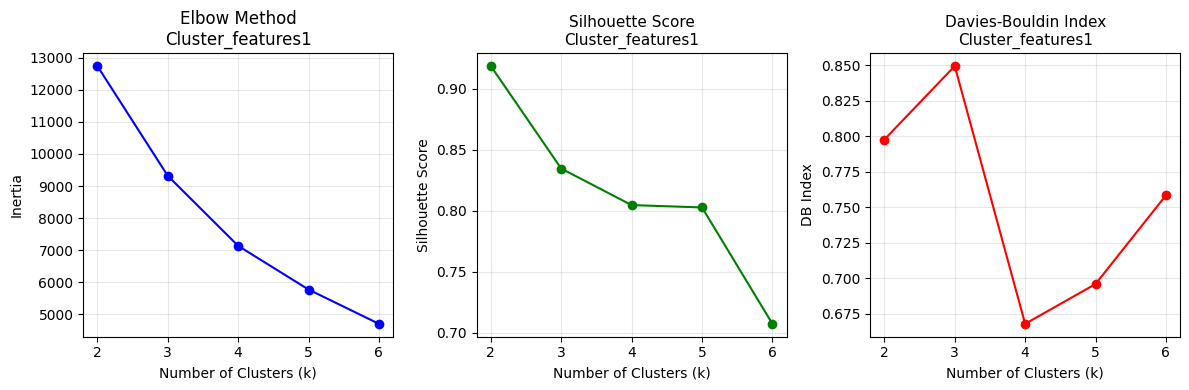

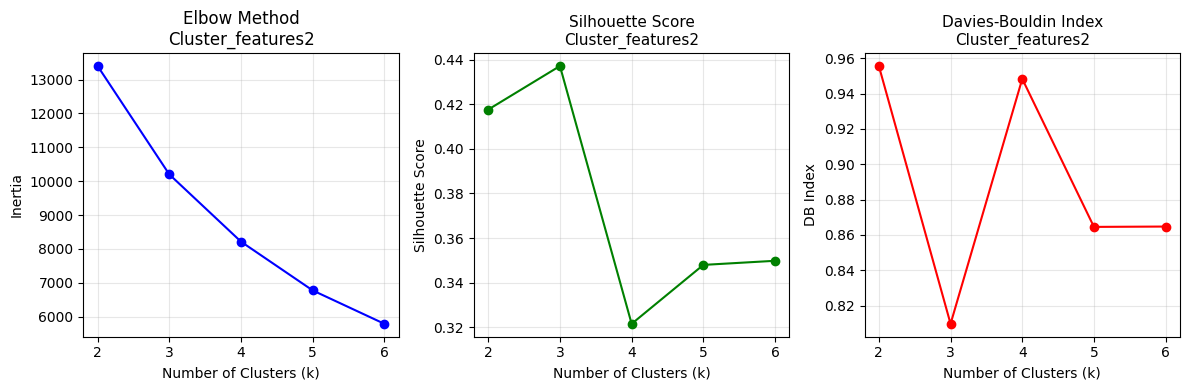

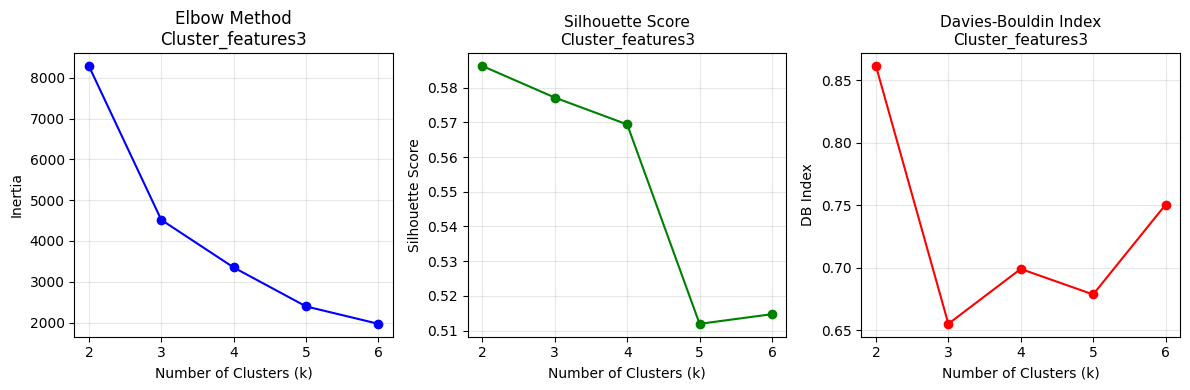

In [230]:
# I will go through my cluster_features so as to get the optimal k for each of my cluster_features and evaluate the clusters.
# this empty list I have created is to have all the cluster_feature combinations appended to it
cluster_finals = []


# next, this loop I have created is so that I dont have to repeat the process 3 times. I can do it once
for cluster_feature_name, cluster_feature_comb in cluster_features.items():
    # first, I get the individual combinations by going through all combinations
    X_cluster = df[cluster_feature_comb]

    # here, I want to fit the combinations with the standardized so that all the features can contribute equally, and there is no bias
    X_scaled = scaler.fit_transform(X_cluster)

    # now, I will try out using silhouette_score, davis_bouldin_score, and k range
    k_range = range(2, 7)
    silhouette_scores = []
    inertia = []
    db_scores = []
    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = kmeans.fit_predict(X_scaled)

        silhouette_scores.append(silhouette_score(X_scaled, labels))
        inertia.append(kmeans.inertia_)
        db_scores.append(davies_bouldin_score(X_scaled, labels))

    # I will use these values to find the best of k
    optimal_k = k_range[np.argmax(silhouette_scores)]

    # next, for the total results, I will add them to a list
    cluster_finals.append({
        'Cluster Feature Combination': cluster_feature_name,
        'Optimal k': optimal_k,
        'Max Silhouette Score': max(silhouette_scores),
        'Min Davies Bouldin': min(db_scores),
        'Inertial': inertia
    })
            

    # now, I will try to make visualizations using silhouette_scores, inertia and db_scores
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 3, 1)
    plt.plot(k_range, inertia, marker='o', color='blue')  
    plt.title(f'Elbow Method\n{cluster_feature_name}')
    plt.xlabel('Number of Clusters (k)')
    plt.ylabel('Inertia')
    plt.grid(True, alpha=0.3)

    # silhouette score
    plt.subplot(1, 3, 2)
    plt.plot(k_range, silhouette_scores, marker='o', color='green')
    plt.title(f'Silhouette Score\n{cluster_feature_name}', fontsize=11)
    plt.xlabel('Number of Clusters (k)')
    plt.ylabel('Silhouette Score')
    plt.grid(True, alpha=0.3)

    #  davis-bouldin

    plt.subplot(1, 3, 3)
    plt.plot(k_range, db_scores, marker='o', color='red')
    plt.title(f'Davies-Bouldin Index\n{cluster_feature_name}', fontsize=11)
    plt.xlabel('Number of Clusters (k)')
    plt.ylabel('DB Index')
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(f'clustering_{cluster_feature_name[:8]}.png', dpi=150)
    plt.show()


    kmeans_total = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
    final_labels = kmeans_total.fit_predict(X_scaled)
        

In [231]:
# showing the dataframe in a view
df_clusters = pd.DataFrame(cluster_finals)
df_clusters

,Cluster Feature Combination,Optimal k,Max Silhouette Score,Min Davies Bouldin,Inertial
0,Cluster_features1,2,0.918582,0.667862,"[12743.313147017212, 9320.106912651621, 7135.6..."
1,Cluster_features2,3,0.437094,0.809638,"[13401.19117295643, 10200.92048796551, 8214.55..."
2,Cluster_features3,2,0.586212,0.655010,"[8288.831174279314, 4517.153338547719, 3349.88..."


/var/folders/qr/1jjdl6z561xg7033nr5m08n00000gn/T/ipykernel_1535/1878257374.py:9: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(x=optimal_features[0], y=optimal_features[1], data=df, palette='viridis')


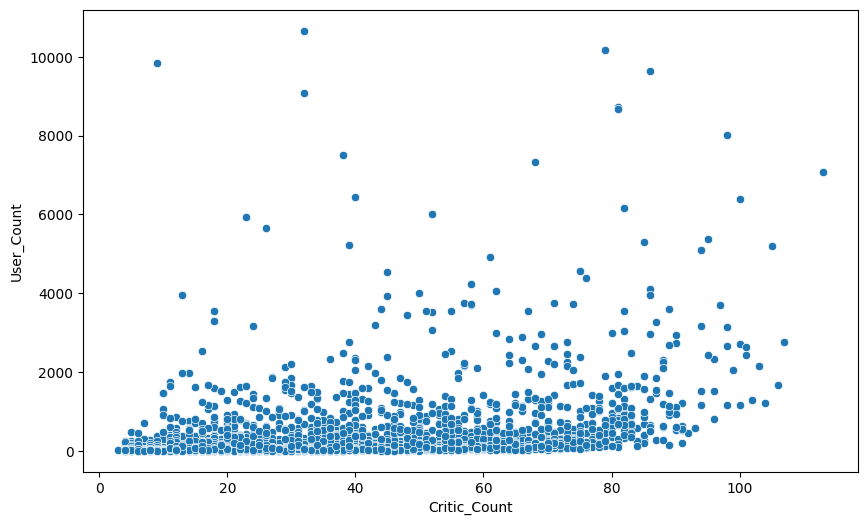

In [232]:
optimal_features = cluster_features['Cluster_features3']
X_optimal = scaler.fit_transform(df[optimal_features])
optimal_k_final = df_clusters.loc[df_clusters['Cluster Feature Combination'] == 'Cluster_features3', 'Optimal k'].values[0]

kmeans_final2 = KMeans(n_clusters=optimal_k_final, random_state=42, n_init=10)
df['Cluster'] = kmeans_final2.fit_predict(X_optimal)

plt.figure(figsize=(10, 6))
sns.scatterplot(x=optimal_features[0], y=optimal_features[1], data=df, palette='viridis')
# plt.title(f'K-Means CLustering: {optimal_features[0]} vs {optimal_features[1] (k={optimal_k_final})')
plt.show()

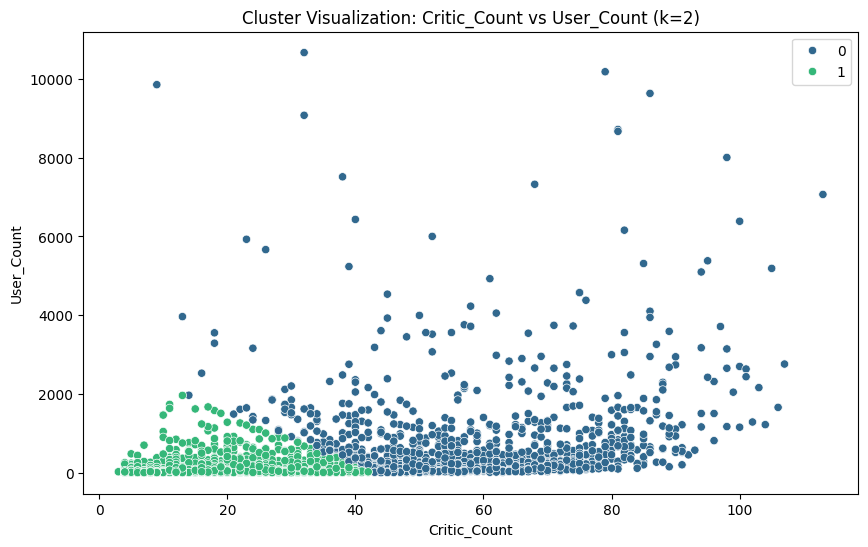

In [233]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df[cluster_feature_comb [0]], y=df[cluster_feature_comb [1]], hue=final_labels, palette='viridis')
plt.title(f'Cluster Visualization: { cluster_feature_comb [0]} vs { cluster_feature_comb [1]} (k={optimal_k})')
plt.show()

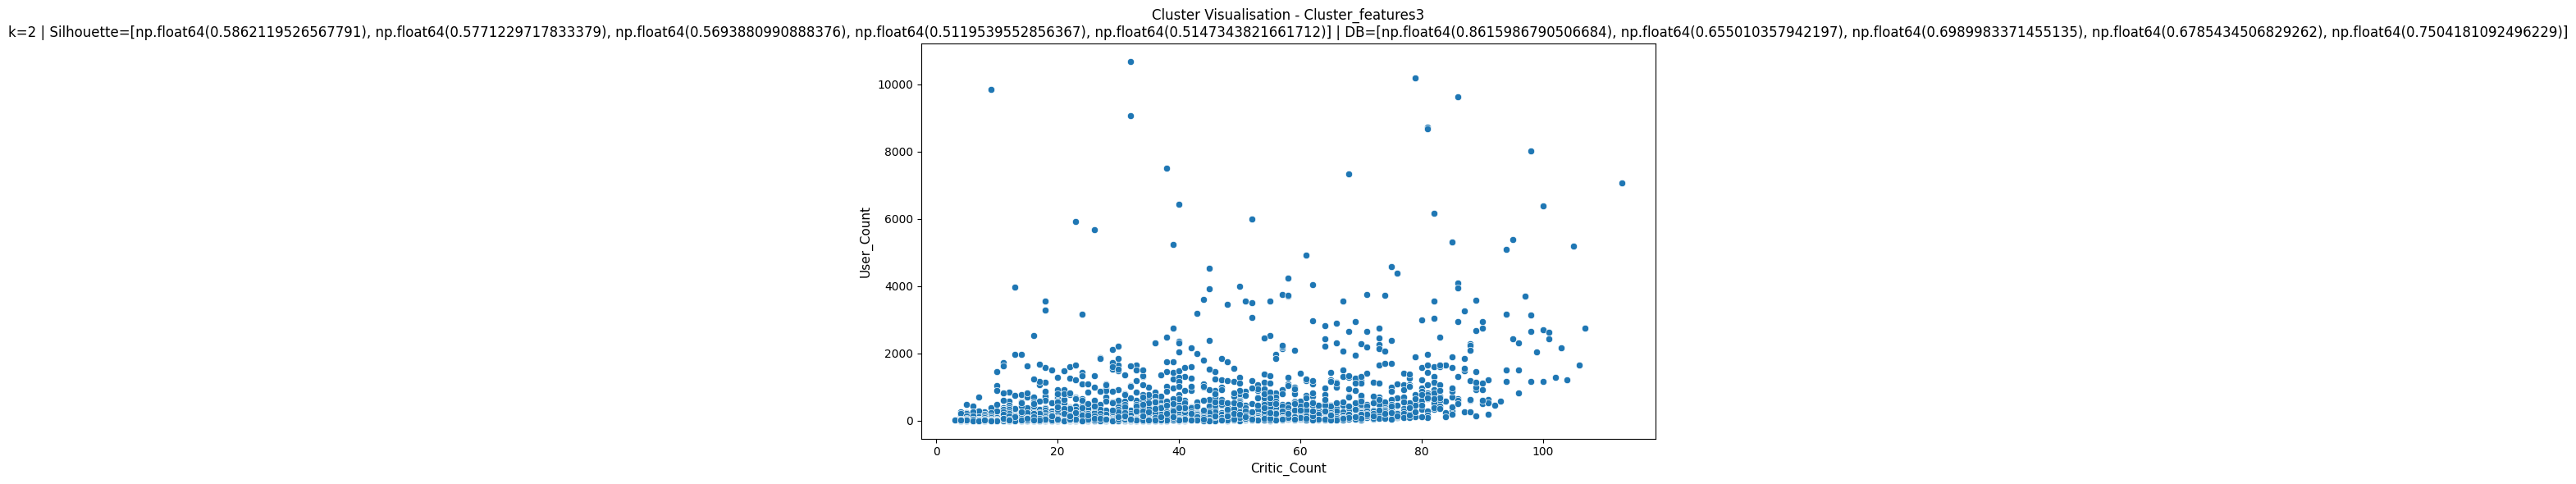

In [234]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df,
                x=cluster_feature_comb[0],
                y=cluster_feature_comb[1],
                # hue=f'{cluster_feature_name}',
                )
plt.title(f'Cluster Visualisation - {cluster_feature_name}\n'
              f'k={optimal_k} | Silhouette={silhouette_scores} | DB={db_scores}', fontsize=12)
plt.xlabel(cluster_feature_comb[0], fontsize=11)
plt.ylabel(cluster_feature_comb[1], fontsize=11)
plt.tight_layout()
plt.savefig(f'scatter_{cluster_feature_name}.png', dpi=150)
plt.show()
    
    # Store results
cluster_finals.append({
        'Configuration':    cluster_feature_name,
        'Features':         ', '.join(cluster_feature_comb),
        'Optimal k':        optimal_k,
        'Silhouette Score': silhouette_scores,
        'Davies-Bouldin':   db_scores,
        'Inertia':          inertia
})

In [235]:
    
# print(f"{cluster_feature_name} | k={optimal_k} | "
#         f"Silhouette={silhouette_scores} | DB={db_scores} | Inertia={inertia}")

# Final Comparison Table
cluster_all = pd.DataFrame(cluster_finals)
display(cluster_all)

,Cluster Feature Combination,Optimal k,Max Silhouette Score,Min Davies Bouldin,Inertial,Configuration,Features,Silhouette Score,Davies-Bouldin,Inertia
0,Cluster_features1,2,0.918582,0.667862,"[12743.313147017212, 9320.106912651621, 7135.6...",NaN,NaN,NaN,NaN,NaN
1,Cluster_features2,3,0.437094,0.809638,"[13401.19117295643, 10200.92048796551, 8214.55...",NaN,NaN,NaN,NaN,NaN
2,Cluster_features3,2,0.586212,0.655010,"[8288.831174279314, 4517.153338547719, 3349.88...",NaN,NaN,NaN,NaN,NaN
3,NaN,2,NaN,NaN,NaN,Cluster_features3,"Critic_Count, User_Count","[0.5862119526567791, 0.5771229717833379, 0.569...","[0.8615986790506684, 0.655010357942197, 0.6989...","[8288.831174279314, 4517.153338547719, 3349.88..."


# Task e
e. Critically justify the performance of your best-performing predictive and clustering
models by drawing on relevant academic literature. Explain why the selected model is
theoretically and empirically suitable for this type of dataset. Include appropriate
scholarly references to support your argument. 

* # Task e result

* Best model:
Predictive / Supervised: Random Forest: R^2 = 0.441
Clustering /Unsupervised: K-Means, cluster_feature1, silhouette score, 0.918582